In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Exploración inicial del dataset

Antes de hacer cualquier transformación, es fundamental entender cómo vienen los datos. En este paso inspeccionamos la estructura del dataset, los tipos de datos y si hay problemas evidentes como columnas mal formateadas o valores faltantes.

In [2]:
# Cargar dataset
df = pd.read_csv("datasets/unprocessed/US Small Cap 2000 Historical Data.csv")

# Ver primeras filas
df.head()

# Información general
df.info()

# Estadísticas básicas
df.describe(include='all')

# Nombres de columnas
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 811 entries, 0 to 810
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      811 non-null    str    
 1   Price     811 non-null    str    
 2   Open      811 non-null    str    
 3   High      811 non-null    str    
 4   Low       811 non-null    str    
 5   Vol.      0 non-null      float64
 6   Change %  811 non-null    str    
dtypes: float64(1), str(6)
memory usage: 44.5 KB


Index(['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %'], dtype='str')

# 2. Corrección de formatos y valores inválidos

Los datos vienen en formato texto (strings), lo cual impide hacer cálculos directamente. Además, las fechas no están en formato datetime y los números contienen comas o símbolos como %.
En este paso convertimos todo a formatos adecuados para análisis numérico y series temporales.

In [3]:
# Copia de seguridad
df_clean = df.copy()

# Convertir fecha
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%m/%d/%Y')

# Ordenar por fecha (importante para LSTM)
df_clean = df_clean.sort_values('Date')

# Limpiar columnas numéricas (eliminar comas)
cols_numeric = ['Price', 'Open', 'High', 'Low']

for col in cols_numeric:
    df_clean[col] = df_clean[col].str.replace(',', '').astype(float)

# Convertir Change % a float
df_clean['Change %'] = df_clean['Change %'].str.replace('%', '').astype(float)

# Volumen → convertir a numérico (vacíos → NaN)
df_clean['Vol.'] = pd.to_numeric(df_clean['Vol.'], errors='coerce')

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 811 entries, 810 to 0
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      811 non-null    datetime64[us]
 1   Price     811 non-null    float64       
 2   Open      811 non-null    float64       
 3   High      811 non-null    float64       
 4   Low       811 non-null    float64       
 5   Vol.      0 non-null      float64       
 6   Change %  811 non-null    float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 44.5 KB


# 3. Análisis de valores nulos e imputación

Ahora evaluamos la calidad de los datos. Identificamos valores nulos y decidimos qué hacer con ellos.
En este caso, la columna Vol. está completamente vacía, por lo que no aporta información y se elimina.

Total de filas: 811
Filas con al menos un nulo: 811
Date: 0 nulos (0.00%)
Price: 0 nulos (0.00%)
Open: 0 nulos (0.00%)
High: 0 nulos (0.00%)
Low: 0 nulos (0.00%)
Vol.: 811 nulos (100.00%)
Change %: 0 nulos (0.00%)


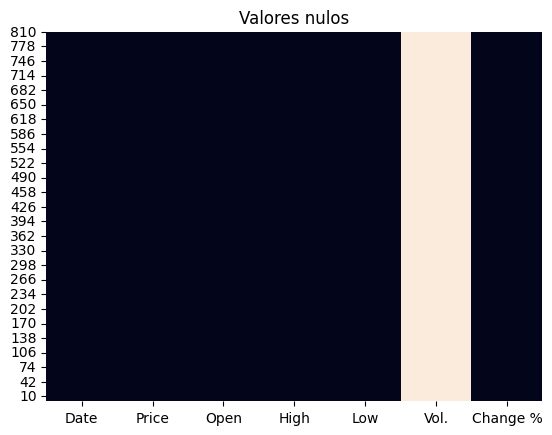

In [4]:
# Ver nulos
df_clean.isnull().sum()
print("Total de filas:", len(df_clean))
print("Filas con al menos un nulo:", df_clean.isnull().any(axis=1).sum())

# Ver nulos por columna
for col in df_clean.columns:
    nulos = df_clean[col].isnull().sum()
    print(f"{col}: {nulos} nulos ({nulos/len(df_clean)*100:.2f}%)")

# Visualizar
sns.heatmap(df_clean.isnull(), cbar=False)
plt.title("Valores nulos")
plt.show()

In [5]:
# Solución: eliminar columna Vol.
df_clean = df_clean.drop(columns=['Vol.'])

# Verificación
df_clean.isnull().sum()

Date        0
Price       0
Open        0
High        0
Low         0
Change %    0
dtype: int64

# 4. Revisión del dataset tras las transformaciones

Una vez limpios los datos, verificamos que todo tenga sentido.
También visualizamos la serie temporal para detectar posibles anomalías o patrones evidentes.

In [6]:
df_clean.head()

,Date,Price,Open,High,Low,Change %
810,2023-01-03,1750.73,1769.75,1785.95,1737.26,-0.60
809,2023-01-04,1772.54,1758.09,1781.97,1758.09,1.25
808,2023-01-05,1753.19,1766.08,1766.08,1745.38,-1.09
807,2023-01-06,1792.80,1764.33,1795.56,1758.50,2.26
806,2023-01-09,1795.91,1801.07,1817.09,1794.54,0.17


In [7]:
df_clean.describe()

,Date,Price,Open,High,Low,Change %
count,811,811.000000,811.000000,811.000000,811.000000,811.000000
mean,2024-08-14 17:41:48.014796,2112.276350,2112.254180,2127.734439,2096.516708,0.047633
min,2023-01-03 00:00:00,1636.940000,1646.360000,1657.320000,1633.670000,-6.590000
25%,2023-10-23 12:00:00,1901.210000,1899.850000,1914.405000,1888.780000,-0.775000
50%,2024-08-14 00:00:00,2070.130000,2074.030000,2086.280000,2056.370000,0.050000
75%,2025-06-07 12:00:00,2281.515000,2281.610000,2291.840000,2270.055000,0.905000
max,2026-03-30 00:00:00,2718.770000,2717.800000,2735.100000,2714.990000,8.660000
std,NaN,257.033016,257.010205,258.647291,255.665871,1.333978


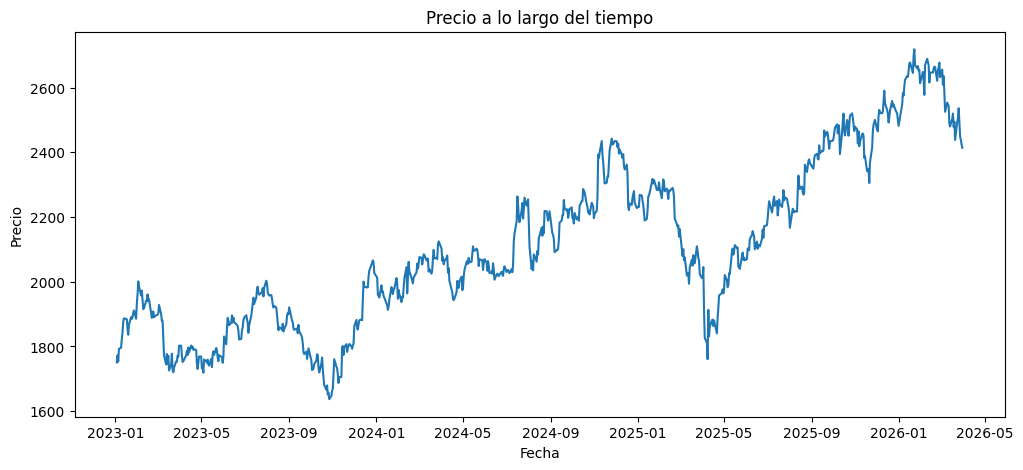

In [8]:
# Visualizar serie temporal
plt.figure(figsize=(12,5))
plt.plot(df_clean['Date'], df_clean['Price'])
plt.title("Precio a lo largo del tiempo")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

Después de convertir correctamente los tipos de datos y eliminar columnas irrelevantes, analizamos los resultados para entender qué información tenemos realmente y si es coherente.

Las primeras filas muestran que los datos están correctamente ordenados por fecha (de más antiguo a más reciente).
Todas las columnas numéricas (Price, Open, High, Low, Change %) tienen valores consistentes y realistas.
Se puede comprobar visualmente que:
- High ≥ Open, Price, Low
- Low ≤ resto de valores
Esto indica que, en general, los datos son coherentes.

Si analizamos las estadísticas:
Precio (Price, Open, High, Low)
- Media ≈ 2112
→ Nivel medio del índice en el periodo analizado.
- Mínimo ≈ 1636 (2023)
→ Punto bajo del mercado, probablemente en contexto bajista.
- Máximo ≈ 2718 (2026)
→ Indica una clara tendencia alcista a lo largo del tiempo.
- Desviación estándar ≈ 257
→ Variabilidad significativa → mercado con volatilidad moderada.

Si observamos:
- Change %
- Media ≈ 0.047%
Podemos interpretar que el mercado sube ligeramente en promedio (que es un comportamiento esperado)

Además:
- Min ≈ -6.59% 
- Max ≈ 8.66%

Nos indica que hay una alta volatilidad ocasional, pero la desviación ≈ 1.33%, así que la variabilidad típica diaria es razonable.

Por lo tanto, los retornos tienen distribución centrada en 0. Hay outliers (movimientos extremos) que conviene tratar.

# 5. Análisis de duplicados

En series temporales, cada fecha debería ser única.
Aquí comprobamos si hay registros duplicados que podrían distorsionar el análisis o el entrenamiento del modelo.

In [9]:
# Filas duplicadas completas
df_clean.duplicated().sum()

np.int64(0)

In [10]:
# Duplicados por fecha
df_clean[df_clean.duplicated(subset=['Date'])]

,Date,Price,Open,High,Low,Change %


# 6. Validación lógica y consistencia matemática

Los datos financieros deben cumplir ciertas reglas:

High debe ser el valor máximo del día
Low debe ser el mínimo

Este paso detecta errores en los datos que podrían afectar al modelo.

In [11]:
invalid_rows = df_clean[
    (df_clean['High'] < df_clean[['Open','Price','Low']].max(axis=1)) |
    (df_clean['Low'] > df_clean[['Open','Price','High']].min(axis=1))
]

invalid_rows

,Date,Price,Open,High,Low,Change %
568,2023-12-19,1982.84,1996.33,2024.25,1995.24,0.02


In [12]:
# Eliminar filas inconsistentes
df_clean = df_clean.drop(invalid_rows.index)

La condición de consistencia dice que Low debe ser el valor mínimo del día
Pero aquí:
Price (1982.84) < Low (1995.24)

Esto es imposible en datos financieros reales, porque el precio de cierre (Price) debe estar dentro del rango [Low, High].

Vamos a eliminarlo porque es un error lógico claro que afecta negativamente al entrenamiento. Es mejor perder 1 fila que introducir ruido estructural.

# 7. Feature Engineering

En este paso se construyen nuevas variables a partir de los datos originales con el objetivo de mejorar la capacidad del modelo para capturar patrones relevantes. En series temporales financieras, trabajar únicamente con precios absolutos suele ser insuficiente, ya que estos presentan tendencia, no son estacionarios y contienen ruido.

En concreto, buscamos introducir estas dimensiones del comportamiento del mercado:

* **Nivel relativo:** con retornos
* **Tendencia:** con medias móviles y momentum
* **Riesgo:** con volatilidad
* **Dinámica diaria:** con rangos y diferencias apertura-cierre

In [13]:
# Retornos
df_clean['return'] = df_clean['Price'].pct_change()

# Media móvil
df_clean['ma_7'] = df_clean['Price'].rolling(window=7).mean()
df_clean['ma_14'] = df_clean['Price'].rolling(window=14).mean()

# Volatilidad
df_clean['volatility_7'] = df_clean['return'].rolling(window=7).std()

# Diferencias
df_clean['high_low_diff'] = df_clean['High'] - df_clean['Low']
df_clean['open_close_diff'] = df_clean['Open'] - df_clean['Price']

# Momentum
df_clean['momentum_7'] = df_clean['Price'] - df_clean['Price'].shift(7)

df_clean.head()

,Date,Price,Open,High,Low,Change %,return,ma_7,ma_14,volatility_7,high_low_diff,open_close_diff,momentum_7
810,2023-01-03,1750.73,1769.75,1785.95,1737.26,-0.60,NaN,NaN,NaN,NaN,48.69,19.02,NaN
809,2023-01-04,1772.54,1758.09,1781.97,1758.09,1.25,0.012458,NaN,NaN,NaN,23.88,-14.45,NaN
808,2023-01-05,1753.19,1766.08,1766.08,1745.38,-1.09,-0.010917,NaN,NaN,NaN,20.70,12.89,NaN
807,2023-01-06,1792.80,1764.33,1795.56,1758.50,2.26,0.022593,NaN,NaN,NaN,37.06,-28.47,NaN
806,2023-01-09,1795.91,1801.07,1817.09,1794.54,0.17,0.001735,NaN,NaN,NaN,22.55,5.16,NaN


**Retornos (`return`)**

Se calcula el cambio porcentual entre precios consecutivos:

Los retornos representan la variación relativa del precio entre dos instantes de tiempo. Esta transformación es fundamental en el análisis financiero porque:

* Reduce el efecto de la tendencia, haciendo la serie más cercana a estacionaria.
* Permite comparar variaciones en distintos niveles de precio.
* Es la base para calcular métricas de riesgo y volatilidad.

En los resultados observados, los retornos presentan valores pequeños alrededor de cero, lo cual es consistente con el comportamiento típico de mercados financieros. La primera fila contiene un valor nulo debido a la ausencia de un dato previo.

**Medias móviles (`ma_7`, `ma_14`)**

Se calculan medias móviles sobre el precio.

Las medias móviles suavizan la serie temporal y permiten identificar la tendencia subyacente eliminando parte del ruido diario.

* La media móvil de 7 días captura la tendencia a corto plazo.
* La media móvil de 14 días proporciona una visión más estable a medio plazo.

En las primeras observaciones aparecen valores nulos, ya que no se dispone de suficientes datos para calcular la media hasta completar la ventana correspondiente. Esto es un comportamiento esperado en variables basadas en ventanas temporales.

**Volatilidad (`volatility_7`)**

Se calcula la desviación estándar de los retornos en una ventana de 7 días.

La volatilidad mide la variabilidad de los retornos y es una aproximación directa al riesgo del activo.

* Valores altos indican mayor incertidumbre y movimientos bruscos.
* Valores bajos reflejan estabilidad en el mercado.

Al igual que en las medias móviles, los valores iniciales son nulos debido a la necesidad de acumular suficientes observaciones.

**Rango diario (`high_low_diff`)**

Se calcula la diferencia entre el máximo y el mínimo diario.

Esta variable mide la amplitud del movimiento intradía y proporciona información sobre la actividad del mercado en cada sesión.

* Un valor alto indica una sesión con alta volatilidad intradía.
* Un valor bajo sugiere un comportamiento más estable.

En los resultados se observan valores como 48.69 o 23.88, lo que indica variabilidad significativa en el rango de precios diarios.

**Diferencia apertura-cierre (`open_close_diff`)**

Se calcula la diferencia entre el precio de apertura y el precio de cierre.

Esta variable captura la dirección del movimiento durante la sesión.

* Valores positivos indican que el precio ha caído a lo largo del día.
* Valores negativos indican que el precio ha subido desde la apertura hasta el cierre.

Por ejemplo, un valor negativo como -14.45 refleja una sesión alcista, mientras que un valor positivo como 19.02 indica presión bajista durante el día.

**Momentum (`momentum_7`)**

Se calcula la diferencia entre el precio actual y el precio de hace 7 días.

El momentum mide la fuerza de la tendencia en un horizonte temporal determinado.

* Valores positivos indican una tendencia alcista.
* Valores negativos indican una tendencia bajista.

Esta variable es especialmente útil para modelos secuenciales, ya que introduce información sobre la evolución acumulada del precio en el tiempo.

# 8. Eliminación de valores nulos

Tras el feature engineering, aparecen valores nulos debido a:

- Cálculo de retornos (pct_change)
- Ventanas temporales (rolling)
- Desplazamientos (shift)

Estos valores no son errores, pero no pueden utilizarse para entrenar el modelo, por lo que deben eliminarse.

El criterio es eliminar todas las filas que contengan al menos un NaN, ya que corresponden al inicio de la serie y no afectan significativamente al volumen total de datos. Estas eliminaciones previstas son parte de la razón por la que hemos reunido tantos datos.

In [14]:
df_model = df_clean.dropna().reset_index(drop=True)

In [15]:
df_model.isnull().sum()

Date               0
Price              0
Open               0
High               0
Low                0
Change %           0
return             0
ma_7               0
ma_14              0
volatility_7       0
high_low_diff      0
open_close_diff    0
momentum_7         0
dtype: int64

# 9. Selección de variables (features y target)

En este paso se definen:

- Variables de entrada (X): las que utilizará el modelo
- Variable objetivo (y): lo que se quiere predecir

Para un modelo LSTM en series temporales financieras, es habitual predecir:
- El precio (Price), o
- El retorno (return)

En este caso, se utilizará el precio como variable objetivo, y el resto como variables explicativas.

In [16]:
features = [
    'Price',
    'Open',
    'High',
    'Low',
    'return',
    'ma_7',
    'ma_14',
    'volatility_7',
    'high_low_diff',
    'open_close_diff',
    'momentum_7'
]

target = 'Price'

X = df_model[features]
y = df_model[target]

Para aclarar, aunque Price está en las features, esto es correcto en LSTM, ya que se utilizan valores pasados para predecir futuros.

# 10. División en train y test

Se separan los datos en entrenamiento y validación. En series temporales no se mezclan los datos, se respeta el orden cronológico.

Se utiliza, por ejemplo, un 80% para entrenamiento y 20% para test.

In [17]:
split = int(0.8 * len(df_model))

X_train_raw = X.iloc[:split]
X_test_raw = X.iloc[split:]

y_train_raw = y.iloc[:split]
y_test_raw = y.iloc[split:]

# 11. Escalado de los datos

Las redes neuronales, y especialmente las LSTM, son sensibles a la escala de los datos. Variables con rangos muy distintos pueden dificultar el aprendizaje.

Se utiliza MinMaxScaler para normalizar los valores en el rango [0, 1]. Esto permite una mejor convergencia del modelo y mayor estabilidad numérica.

In [18]:
from sklearn.preprocessing import MinMaxScaler

# Escalar X
scaler_x = MinMaxScaler()

X_train_scaled = scaler_x.fit_transform(X_train_raw)
X_test_scaled = scaler_x.transform(X_test_raw)

# Escalar y
scaler_y = MinMaxScaler()

y_train_scaled = scaler_y.fit_transform(y_train_raw.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test_raw.values.reshape(-1, 1))

# 12. Creación de secuencias temporales (timesteps)

Las LSTM no trabajan con filas independientes, sino con secuencias de datos. Por ello, se deben transformar los datos en ventanas temporales.

Por ejemplo: Usar los últimos 10 días para predecir el siguiente.

In [19]:
import numpy as np

def create_sequences(X, y, time_steps=10):
    X_seq = []
    y_seq = []
    
    for i in range(len(X) - time_steps):
        X_seq.append(X[i:i+time_steps])
        y_seq.append(y[i+time_steps])
    
    return np.array(X_seq), np.array(y_seq)

time_steps = 10

# Crear secuencias separadas
X_train, y_train = create_sequences(X_train_scaled, y_train_scaled, time_steps)
X_test, y_test = create_sequences(X_test_scaled, y_test_scaled, time_steps)

Y cambiamos a float para mejorar el rendimiento.

In [20]:
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)
y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

# 13. Comprobación final de dimensiones

Antes de entrenar el modelo, es importante verificar que las dimensiones son correctas:

In [21]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (627, 10, 11)
X_test shape: (150, 10, 11)
y_train shape: (627, 1)
y_test shape: (150, 1)


# 14. Guardar datos limpios

In [22]:
df_model.to_csv("datasets/processed/dataset_limpio.csv", index=False)

In [23]:
np.save("datasets/processed/X_train.npy", X_train)
np.save("datasets/processed/X_test.npy", X_test)
np.save("datasets/processed/y_train.npy", y_train)
np.save("datasets/processed/y_test.npy", y_test)

Guardamos X_train, X_test, y_train y y_test como archivos .npy porque son matrices multidimensionales (3D en el caso de X para LSTM: [samples, timesteps, features]). 

Los archivos CSV están pensados para datos tabulares 2D y no soportan directamente estructuras de más dimensiones, lo que complicaría su lectura y reconstitución. 
.npy conserva la estructura original, los tipos de datos y permite cargar los arrays directamente en NumPy sin necesidad de transformar o reconstruir las dimensiones, ahorrando tiempo y evitando errores.